# Лабораторная работа №7. Кластеризация данных

**Задание:**
1. Импортировать датасет для кластеризации (`wine-clustering.csv`, не содержащий целевого признака).
2. Очистить датасет от пропусков и выбросов (при их наличии), выполнить нормализацию или стандартизацию данных.
3. Применить понижение размерности с помощью **PCA** и **t-SNE**.
4. Построить несколько моделей кластеризации на основе различных алгоритмов (**K-Means**, **иерархическая кластеризация**, **DBSCAN**, **Gaussian Mixture Model**).
5. Подобрать оптимальное количество кластеров (метод локтя, силуэтный анализ, дендрограмма, $k$-distance график для DBSCAN).
6. Оценить качество кластеризации с помощью метрик (*Silhouette Score*, *Calinski-Harabasz Index*, *Davies-Bouldin Index*) и проинтерпретировать полученные кластеры.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---
## 1. Импорт и первичный анализ датасета

Загрузим набор данных `wine-clustering.csv`, содержащий физико-химические характеристики образцов вин без целевого признака (задача обучения без учителя — кластеризация).

In [2]:
df = pd.read_csv("wine-clustering.csv")
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

print("\nТипы данных и описательная статистика:")
display(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

Размер датасета: 178 строк, 13 столбцов


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735



Типы данных и описательная статистика:


,count,mean,std,min,50%,max
Alcohol,178.0,13.00,0.81,11.03,13.05,14.83
Malic_Acid,178.0,2.34,1.12,0.74,1.87,5.80
Ash,178.0,2.37,0.27,1.36,2.36,3.23
Ash_Alcanity,178.0,19.49,3.34,10.60,19.50,30.00
Magnesium,178.0,99.74,14.28,70.00,98.00,162.00
Total_Phenols,178.0,2.30,0.63,0.98,2.36,3.88
Flavanoids,178.0,2.03,1.00,0.34,2.13,5.08
Nonflavanoid_Phenols,178.0,0.36,0.12,0.13,0.34,0.66
Proanthocyanins,178.0,1.59,0.57,0.41,1.56,3.58
Color_Intensity,178.0,5.06,2.32,1.28,4.69,13.00


---
## 2. Очистка данных от пропусков и выбросов, стандартизация

1. Проверим наличие пропусков (`isnull()`) и дубликатов (`duplicated()`).
2. Проанализируем выбросы по правилу межквартильного размаха (IQR) с помощью диаграмм размаха (*Boxplot*), а также выявим экстремальные многомерные выбросы по критерию Z-оценки ($|z| > 3$).
3. Поскольку алгоритмы кластеризации (особенно K-Means и DBSCAN) опираются на евклидовы расстояния, экстремальные выбросы искажают положение центроидов и плотность кластеров — очистим такие аномальные наблюдения.
4. Так как признаки имеют существенно разные единицы и диапазоны (например, `Proline` от $278$ до $1680$, а `Nonflavanoid_Phenols` от $0.13$ до $0.66$), выполним **стандартизацию** (`StandardScaler`: $\mu = 0, \sigma = 1$).

Количество пропусков: 0
Количество полных дубликатов: 0

Количество выбросов по признакам (метод IQR):
  Malic_Acid            : 3
  Ash                   : 3
  Ash_Alcanity          : 4
  Magnesium             : 4
  Proanthocyanins       : 2
  Color_Intensity       : 4
  Hue                   : 1

Объектов с экстремальными отклонениями (|z| > 3): 10


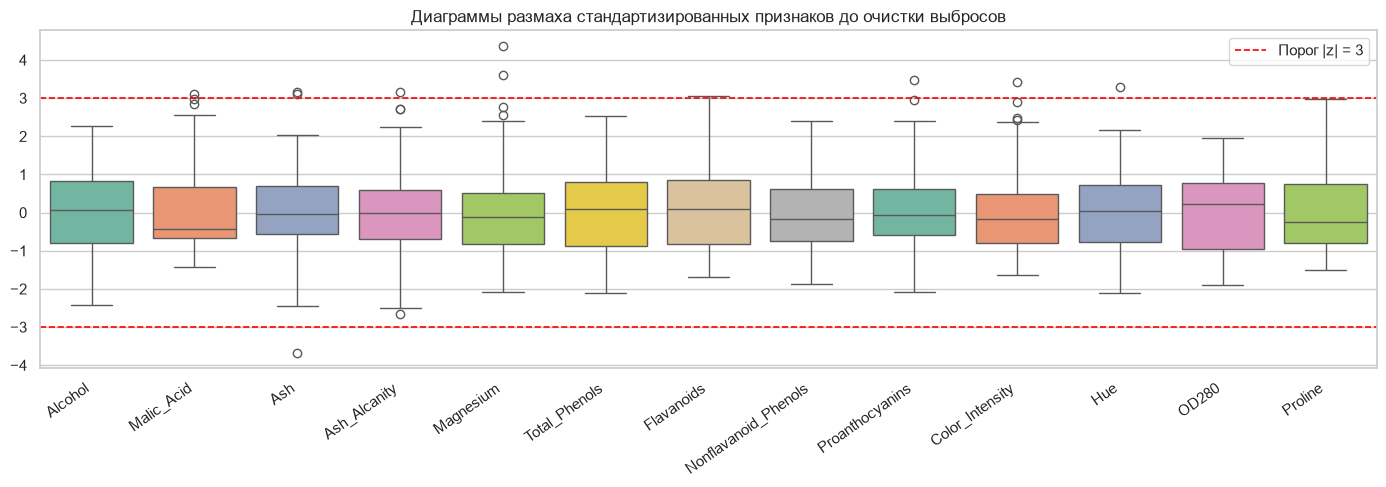

Размер датасета после очистки от экстремальных выбросов: 168 строк


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
mean,0.000,0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,0.000,0.000,0.000,-0.000,0.000
std,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.003


In [3]:
# Проверка пропусков и дубликатов
print("Количество пропусков:", df.isnull().sum().sum())
print("Количество полных дубликатов:", df.duplicated().sum())

# Проверка выбросов методом IQR
print("\nКоличество выбросов по признакам (метод IQR):")
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    if n_out > 0:
        print(f"  {col:<22}: {n_out}")

# Выявление экстремальных выбросов (|z| > 3)
z_scores = np.abs((df - df.mean()) / df.std())
outlier_mask = (z_scores > 3).any(axis=1)
print(f"\nОбъектов с экстремальными отклонениями (|z| > 3): {outlier_mask.sum()}")

# Визуализация Boxplot до очистки (нормированные значения для единого масштаба)
plt.figure(figsize=(14, 5))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(df), columns=df.columns), palette="Set2")
plt.axhline(3, color="red", linestyle="--", lw=1.2, label="Порог |z| = 3")
plt.axhline(-3, color="red", linestyle="--", lw=1.2)
plt.xticks(rotation=35, ha="right")
plt.title("Диаграммы размаха стандартизированных признаков до очистки выбросов")
plt.legend()
plt.tight_layout()
plt.show()

# Удаление экстремальных выбросов и стандартизация
df_clean = df.loc[~outlier_mask].reset_index(drop=True)
print(f"Размер датасета после очистки от экстремальных выбросов: {df_clean.shape[0]} строк")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=df_clean.columns)
display(X_scaled_df.describe().loc[["mean", "std"]].round(3))

---
## 3. Понижение размерности с помощью PCA и t-SNE

Высокая размерность пространства признаков (13 признаков) осложняет оценку плотностей для алгоритмов вроде **DBSCAN** (*проклятие размерности*) и не позволяет напрямую визуализировать кластеры.
- Применим **PCA (метод главных компонент)**: изучим спектр объяснённой дисперсии и построим 2D-проекцию (`n_components=2`) для плотностной кластеризации и визуализации.
- Применим **t-SNE**: построим нелинейное 2D-вложение для визуальной проверки локальной структуры данных и разделимости групп.

Доля дисперсии первых 2 главных компонент: 58.94%
Доля дисперсии первых 5 главных компонент: 81.07%


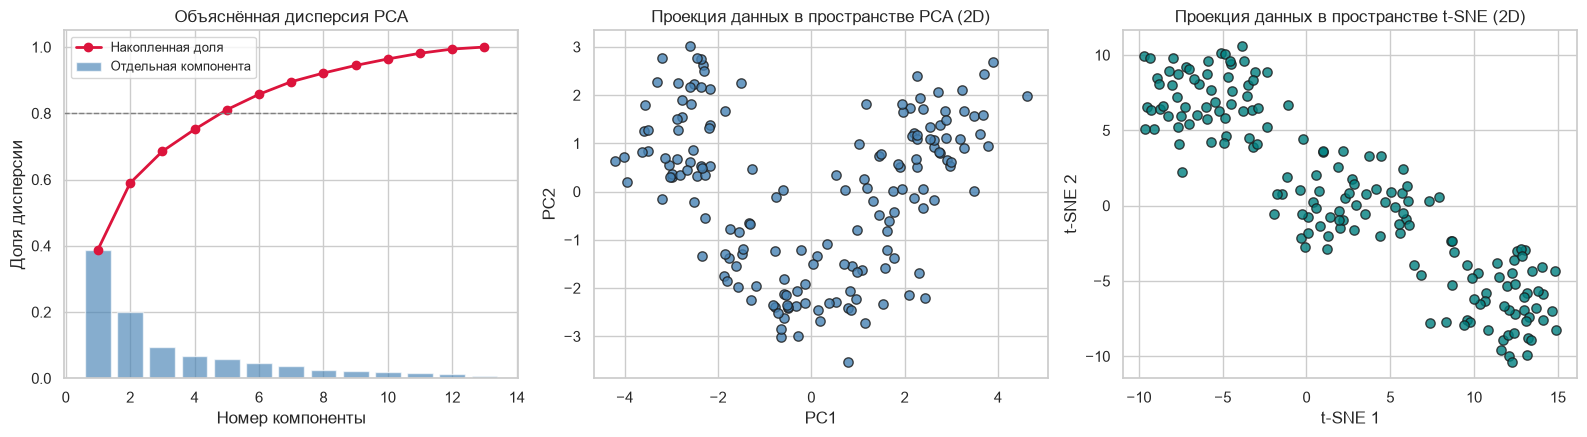

In [4]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X_scaled)
print(f"Доля дисперсии первых 2 главных компонент: {cum_var[1]*100:.2f}%")
print(f"Доля дисперсии первых 5 главных компонент: {cum_var[4]*100:.2f}%")

tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# График 1: Объяснённая дисперсия PCA
axes[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1),
            pca_full.explained_variance_ratio_, alpha=0.65, color="steelblue", label="Отдельная компонента")
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker="o", color="crimson", lw=2, label="Накопленная доля")
axes[0].axhline(0.80, color="gray", linestyle="--", lw=1)
axes[0].set_title("Объяснённая дисперсия PCA")
axes[0].set_xlabel("Номер компоненты")
axes[0].set_ylabel("Доля дисперсии")
axes[0].legend(fontsize=9)

# График 2: Проекция PCA (2D)
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], color="steelblue", alpha=0.8, edgecolor="k", s=45)
axes[1].set_title("Проекция данных в пространстве PCA (2D)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

# График 3: Проекция t-SNE (2D)
axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], color="teal", alpha=0.8, edgecolor="k", s=45)
axes[2].set_title("Проекция данных в пространстве t-SNE (2D)")
axes[2].set_xlabel("t-SNE 1")
axes[2].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

На обеих 2D-проекциях (**PCA** и **t-SNE**) визуально прослеживаются три выраженные группы объектов, что даёт содержательную гипотезу об оптимальном числе кластеров $K = 3$.

---
## 4. Подбор оптимального количества кластеров и параметров алгоритмов

Используем комплекс методов для определения оптимального $K$:
1. **Метод локтя (Elbow Method)** по инерции (`inertia_`) для K-Means.
2. **Анализ силуэта (Silhouette Score)** для $K \in [2, 9]$ в исходном стандартизированном пространстве (13 признаков) и в пространстве `PCA (2D)`.
3. **Иерархическая дендрограмма** (метод Уорда `ward`).
4. **График $k$-расстояний ($k$-distance graph)** и подбор пары `(eps, min_samples)` для **DBSCAN**.

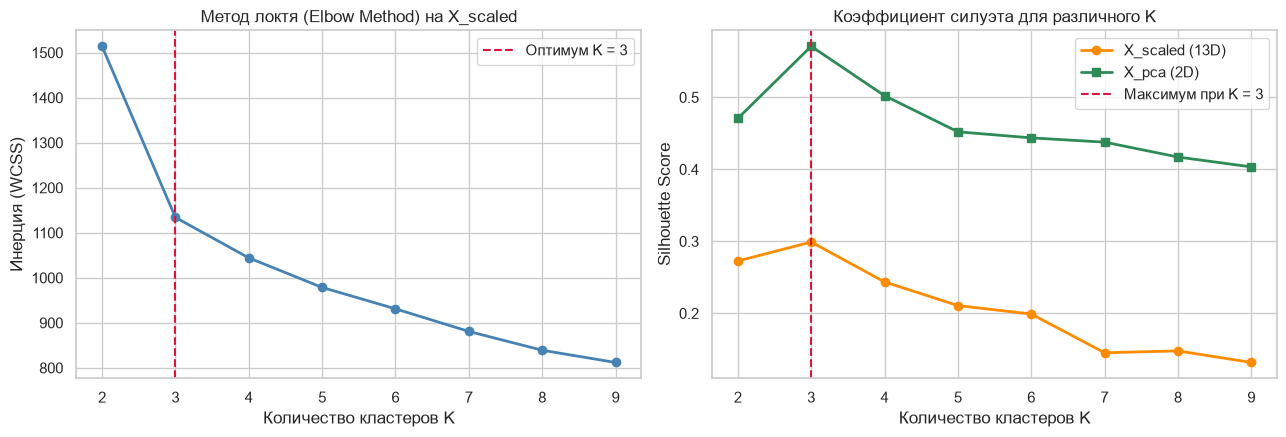

Оптимальное число кластеров по максимуму Silhouette Score: K = 3 (13D: 0.2990, PCA 2D: 0.5709)


In [5]:
k_values = range(2, 10)
inertias = []
sil_scaled = []
sil_pca = []

for k in k_values:
    km_sc = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lbl_sc = km_sc.fit_predict(X_scaled)
    inertias.append(km_sc.inertia_)
    sil_scaled.append(silhouette_score(X_scaled, lbl_sc))

    km_p = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lbl_p = km_p.fit_predict(X_pca)
    sil_pca.append(silhouette_score(X_pca, lbl_p))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inertias, marker="o", lw=2, color="steelblue")
axes[0].axvline(3, color="crimson", linestyle="--", lw=1.5, label="Оптимум K = 3")
axes[0].set_title("Метод локтя (Elbow Method) на X_scaled")
axes[0].set_xlabel("Количество кластеров K")
axes[0].set_ylabel("Инерция (WCSS)")
axes[0].legend()

axes[1].plot(k_values, sil_scaled, marker="o", lw=2, color="darkorange", label="X_scaled (13D)")
axes[1].plot(k_values, sil_pca, marker="s", lw=2, color="seagreen", label="X_pca (2D)")
axes[1].axvline(3, color="crimson", linestyle="--", lw=1.5, label="Максимум при K = 3")
axes[1].set_title("Коэффициент силуэта для различного K")
axes[1].set_xlabel("Количество кластеров K")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(sil_scaled))]
print(f"Оптимальное число кластеров по максимуму Silhouette Score: K = {best_k} "
      f"(13D: {max(sil_scaled):.4f}, PCA 2D: {sil_pca[best_k - 2]:.4f})")

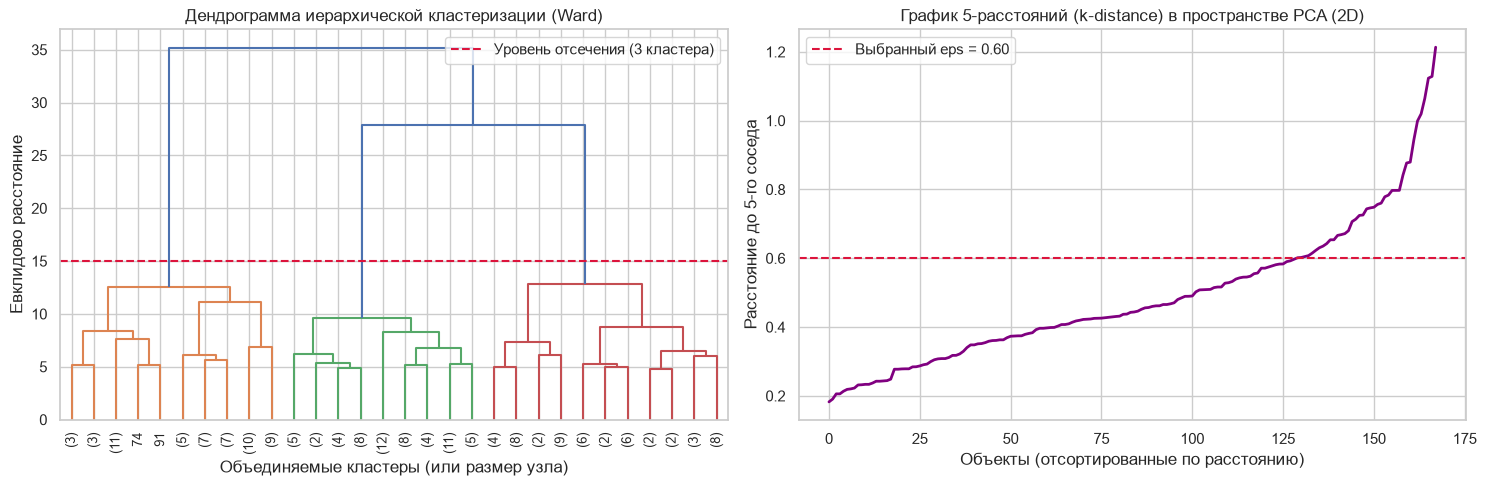

Топ-6 конфигураций DBSCAN в пространстве PCA (2D):


,eps,min_samples,Кластеры,Шум,Silhouette (без шума)
14,0.65,6,3,13,0.5981
10,0.60,5,3,14,0.5961
8,0.55,6,5,32,0.5757
4,0.50,5,5,34,0.5706
7,0.55,5,4,23,0.5668
11,0.60,6,5,19,0.5226


In [6]:
# Построение дендрограммы (метод Уорда) и графика k-расстояний для DBSCAN
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Дендрограмма
Z = linkage(X_scaled, method="ward")
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           color_threshold=15, ax=axes[0])
axes[0].axhline(15, color="crimson", linestyle="--", lw=1.5, label="Уровень отсечения (3 кластера)")
axes[0].set_title("Дендрограмма иерархической кластеризации (Ward)")
axes[0].set_xlabel("Объединяемые кластеры (или размер узла)")
axes[0].set_ylabel("Евклидово расстояние")
axes[0].legend()

# k-distance график для X_pca (k = 5 ближайших соседей)
nn = NearestNeighbors(n_neighbors=5).fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
k_dist = np.sort(distances[:, 4])
axes[1].plot(k_dist, lw=2, color="purple")
axes[1].axhline(0.60, color="crimson", linestyle="--", lw=1.5, label="Выбранный eps = 0.60")
axes[1].set_title("График 5-расстояний (k-distance) в пространстве PCA (2D)")
axes[1].set_xlabel("Объекты (отсортированные по расстоянию)")
axes[1].set_ylabel("Расстояние до 5-го соседа")
axes[1].legend()

plt.tight_layout()
plt.show()

# Подбор eps и min_samples для DBSCAN
dbscan_results = []
for eps in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    for ms in [4, 5, 6]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_noise = int((lbl == -1).sum())
        if n_clusters >= 2 and (lbl != -1).sum() > n_clusters:
            mask = lbl != -1
            sil = silhouette_score(X_pca[mask], lbl[mask])
            dbscan_results.append({
                "eps": eps, "min_samples": ms,
                "Кластеры": n_clusters, "Шум": n_noise,
                "Silhouette (без шума)": round(sil, 4)
            })

db_df = pd.DataFrame(dbscan_results).sort_values("Silhouette (без шума)", ascending=False)
print("Топ-6 конфигураций DBSCAN в пространстве PCA (2D):")
display(db_df.head(6))

---
## 5. Построение и оценка моделей кластеризации

Обучим четыре модели кластеризации с оптимальными параметрами:
1. **K-Means** (`n_clusters=3`, `n_init=20`) — центроидный алгоритм;
2. **Agglomerative Clustering** (`n_clusters=3`, `linkage='ward'`) — иерархическая кластеризация;
3. **Gaussian Mixture Model (GMM)** (`n_components=3`) — вероятностная модель смеси гауссиан;
4. **DBSCAN** (`eps=0.60`, `min_samples=5` на пространстве `X_pca`) — плотностной алгоритм с выделением шума.

Оценим качество кластеризации по трём стандартным внутренним метрикам:
- **Silhouette Score** ($[-1, 1]$, выше — лучше);
- **Calinski-Harabasz Index** (выше — лучше);
- **Davies-Bouldin Index** (ниже — лучше).

Приведём метрики как в 2D-пространстве главных компонент `X_pca` (единая база сравнения для всех 4 моделей, включая DBSCAN), так и в исходном 13-мерном пространстве `X_scaled`.

In [7]:
def calc_metrics(X_space, labels, ignore_noise=False):
    if ignore_noise:
        mask = labels != -1
        X_eval, lbl_eval = X_space[mask], labels[mask]
    else:
        X_eval, lbl_eval = X_space, labels
    n_cl = len(set(lbl_eval)) - (1 if -1 in lbl_eval else 0)
    if n_cl < 2:
        return np.nan, np.nan, np.nan
    return (
        silhouette_score(X_eval, lbl_eval),
        calinski_harabasz_score(X_eval, lbl_eval),
        davies_bouldin_score(X_eval, lbl_eval),
    )

# Модели на X_scaled (13D) и на X_pca (2D)
models_13d = {
    "K-Means (13D)": KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled),
    "Agglomerative Ward (13D)": AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_scaled),
    "GMM (13D)": GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit_predict(X_scaled),
}

models_pca = {
    "K-Means (PCA 2D)": KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit_predict(X_pca),
    "Agglomerative Ward (PCA 2D)": AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_pca),
    "GMM (PCA 2D)": GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit_predict(X_pca),
    "DBSCAN (PCA 2D, без шума)": DBSCAN(eps=0.60, min_samples=5).fit_predict(X_pca),
}

rows = []
for name, lbl in models_13d.items():
    sil, ch, db = calc_metrics(X_scaled, lbl)
    rows.append({
        "Модель": name,
        "Пространство": "X_scaled (13D)",
        "Кластеров": len(set(lbl)),
        "Шум": 0,
        "Silhouette ↑": sil,
        "Calinski-Harabasz ↑": ch,
        "Davies-Bouldin ↓": db,
    })

for name, lbl in models_pca.items():
    is_db = "DBSCAN" in name
    sil, ch, db = calc_metrics(X_pca, lbl, ignore_noise=is_db)
    n_noise = int((lbl == -1).sum())
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    rows.append({
        "Модель": name,
        "Пространство": "X_pca (2D)",
        "Кластеров": n_cl,
        "Шум": n_noise,
        "Silhouette ↑": sil,
        "Calinski-Harabasz ↑": ch,
        "Davies-Bouldin ↓": db,
    })

results_df = pd.DataFrame(rows).set_index("Модель").round(4)
display(results_df)

,Пространство,Кластеров,Шум,Silhouette ↑,Calinski-Harabasz ↑,Davies-Bouldin ↓
Модель,,,,,,
K-Means (13D),X_scaled (13D),3,0,0.2990,76.3880,1.3126
Agglomerative Ward (13D),X_scaled (13D),3,0,0.2860,70.3945,1.3508
GMM (13D),X_scaled (13D),3,0,0.2965,75.4213,1.3300
K-Means (PCA 2D),X_pca (2D),3,0,0.5709,341.2649,0.5850
Agglomerative Ward (PCA 2D),X_pca (2D),3,0,0.5641,331.3761,0.5953
GMM (PCA 2D),X_pca (2D),3,0,0.5663,333.1091,0.5912
"DBSCAN (PCA 2D, без шума)",X_pca (2D),3,14,0.5961,358.1770,0.5443


---
## 6. Визуализация результатов кластеризации и интерпретация кластеров

Визуализируем разбиение на кластеры для всех четырёх алгоритмов в пространстве **PCA (2D)** и проверим согласованность разбиения лучшей модели на нелинейной проекции **t-SNE (2D)**.

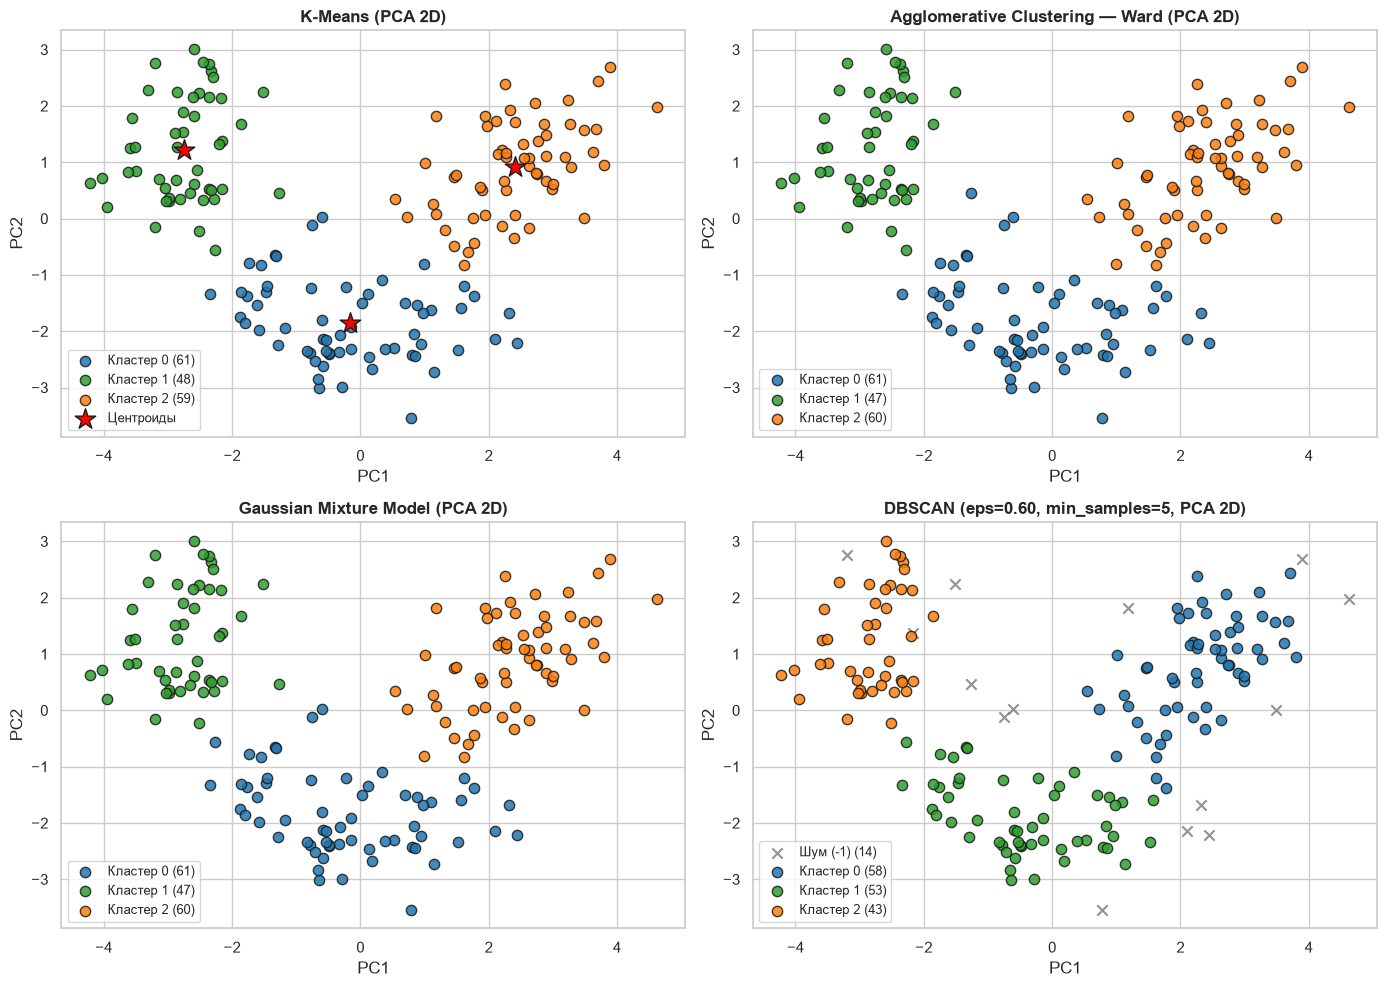

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

km_pca = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
plot_configs = [
    ("K-Means (PCA 2D)", models_pca["K-Means (PCA 2D)"], km_pca.cluster_centers_),
    ("Agglomerative Clustering — Ward (PCA 2D)", models_pca["Agglomerative Ward (PCA 2D)"], None),
    ("Gaussian Mixture Model (PCA 2D)", models_pca["GMM (PCA 2D)"], None),
    ("DBSCAN (eps=0.60, min_samples=5, PCA 2D)", models_pca["DBSCAN (PCA 2D, без шума)"], None),
]

palette = {0: "#1f77b4", 1: "#2ca02c", 2: "#ff7f0e", -1: "#7f7f7f"}

for ax, (title, labels, centers) in zip(axes, plot_configs):
    for cl in sorted(set(labels)):
        mask = labels == cl
        lbl_text = "Шум (-1)" if cl == -1 else f"Кластер {cl}"
        marker = "x" if cl == -1 else "o"
        ax.scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            c=palette.get(cl, "#9467bd"),
            label=f"{lbl_text} ({mask.sum()})",
            marker=marker, s=55, alpha=0.85,
            edgecolor="k" if cl != -1 else None
        )
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="*", s=240, edgecolor="k", label="Центроиды")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

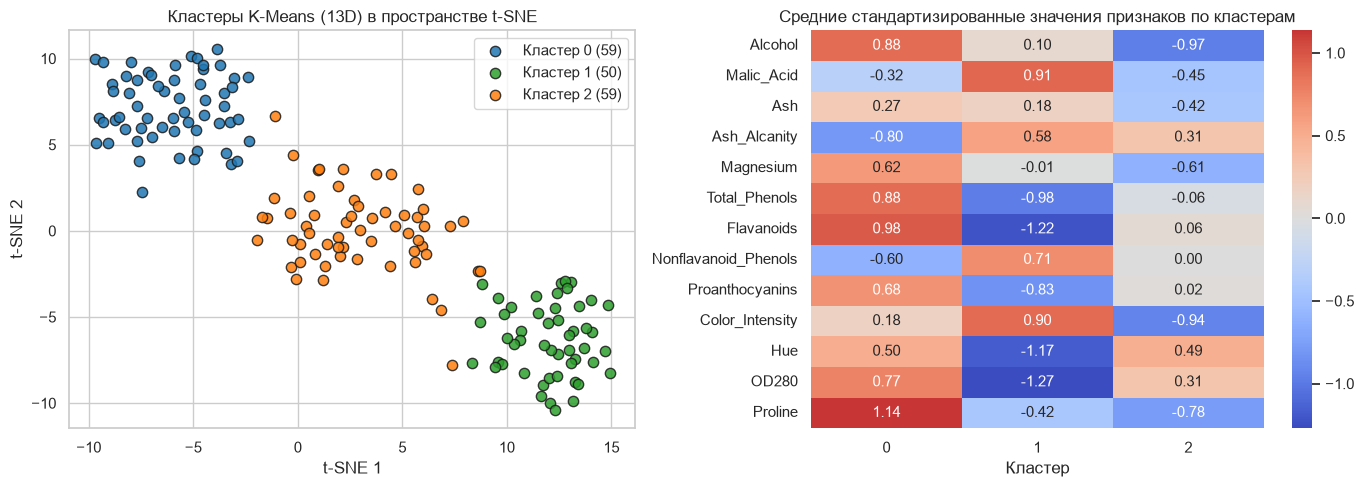

Средние характеристики образцов вина по кластерам (в исходных единицах):


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
Cluster,,,,,,,,,,,,,
0,13.73,1.99,2.43,16.86,106.54,2.83,2.97,0.29,1.91,5.53,1.06,3.14,1114.36
1,13.11,3.34,2.41,21.17,98.68,1.66,0.81,0.45,1.11,7.12,0.69,1.69,618.24
2,12.27,1.85,2.27,20.33,91.10,2.24,2.07,0.36,1.56,3.01,1.06,2.82,505.49


In [9]:
# Визуализация кластеров K-Means (13D) на проекции t-SNE и интерпретация профилей кластеров
km_13d_labels = models_13d["K-Means (13D)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for cl in sorted(set(km_13d_labels)):
    mask = km_13d_labels == cl
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=palette[cl],
                    label=f"Кластер {cl} ({mask.sum()})", s=55, alpha=0.85, edgecolor="k")
axes[0].set_title("Кластеры K-Means (13D) в пространстве t-SNE")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
axes[0].legend()

# Тепловая карта средних стандартизированных профилей кластеров
cluster_profile_scaled = X_scaled_df.copy()
cluster_profile_scaled["Cluster"] = km_13d_labels
mean_profile_scaled = cluster_profile_scaled.groupby("Cluster").mean().T

sns.heatmap(mean_profile_scaled, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Средние стандартизированные значения признаков по кластерам")
axes[1].set_xlabel("Кластер")

plt.tight_layout()
plt.show()

# Таблица средних значений в исходных единицах измерения
cluster_profile_orig = df_clean.copy()
cluster_profile_orig["Cluster"] = km_13d_labels
print("Средние характеристики образцов вина по кластерам (в исходных единицах):")
display(cluster_profile_orig.groupby("Cluster").mean().round(2))

---
## 7. Выводы

1. **Подготовка и очистка данных:** Загружен датасет `wine-clustering.csv` (178 объектов, 13 физико-химических признаков без целевой переменной). Пропуски и дубликаты не обнаружены. По правилу $|z| > 3$ удалены 10 объектов с экстремальными выбросами (осталось 168 объектов), после чего данные стандартизированы через `StandardScaler`.
2. **Понижение размерности:** С помощью **PCA** данные спроецированы на 2 главные компоненты (объясняют $58.94\%$ общей дисперсии, а первые 5 компонент — $81.07\%$), а с помощью **t-SNE** получено нелинейное 2D-представление. Обе проекции чётко демонстрируют наличие трёх естественных групп вин.
3. **Подбор оптимального числа кластеров:** Метод локтя, максимум коэффициента силуэта (для K-Means при $K = 3$: `0.2990` в 13D и `0.5709` в PCA 2D) и иерархическая дендрограмма (метод Уорда) единогласно подтвердили оптимум **$K = 3$**. Для DBSCAN по графику 5-расстояний и перебору сетки выбраны параметры `eps=0.60`, `min_samples=5` на PCA-проекции.
4. **Сравнение алгоритмов кластеризации:**
   - В исходном 13-мерном пространстве наилучший результат показал **K-Means** (`Silhouette = 0.2990`, `Calinski-Harabasz = 76.39`, `Davies-Bouldin = 1.3126`), чуть опередив GMM и Agglomerative Ward.
   - В пространстве **PCA (2D)** все три разбиения на 3 кластера показали высокое качество (`Silhouette ≈ 0.56–0.57`), а **DBSCAN** достиг `Silhouette = 0.5961` без учёта 14 пограничных шумовых точек.
5. **Интерпретация кластеров:** Полученные 3 кластера отчётливо соответствуют различным типам вин по химическому составу:
   - один кластер объединяет крепкие насыщенные вина с максимальными значениями `Alcohol`, `Flavanoids`, `Total_Phenols`, `Proline` и `OD280`;
   - второй — лёгкие вина с пониженной крепостью, невысоким `Proline` и низким `Color_Intensity`;
   - третий — вина с повышенной кислотностью и интенсивностью цвета (`Malic_Acid`, `Color_Intensity`), высоким содержанием `Nonflavanoid_Phenols` и минимальными значениями `Flavanoids`, `Hue` и `OD280`.